# 07 · Rigorous model evaluation

**Objective.** Compare every model on the **same test period, horizons, targets and rules**, answer the research question
*"does using the road graph improve multi-step forecasting compared with treating sensors independently?"*, and look at where the answer holds or fails
(peak vs off-peak, sensor by sensor).

**Inputs.** Saved test predictions of persistence, rolling mean, seasonal average, XGBoost, ST-GAT, the no-edge ST-GAT ablation and, if it was run, DCRNN.
**A model without a prediction file is reported as missing; its metrics are never invented.**

**Metrics** (`src/metrics.py`). A point is valid if its true speed was observed and every compared model produced a finite forecast
(*common valid mask*).
* **MAE** = mean(|ŷ − y|), **RMSE** = sqrt(mean((ŷ − y)²)), both in mph, pooled over all valid (sample, sensor) points of a horizon.
* **MAPE** = 100·mean(|ŷ − y| / y) in %, only for true speeds ≥ 1 mph (near-zero policy); `n_valid_mape` is reported next to it.
* Predictions of every model are clipped to the physical range 0-70 mph before scoring (identical rule for all).
* **Improvement of model B over model A** = `100 × (error_A − error_B) / error_A`. **Positive means B has the lower error (B is better).**
  Confidence intervals come from a **day-block bootstrap** (whole days resampled, 2,000 draws), because errors within a day are strongly correlated.

**Peak vs off-peak** were defined *before* any model ran (`config.PEAK_WINDOWS`): weekdays 07:00-10:00 and 15:00-19:00, judged on the **forecast target time**,
assuming timestamps are Pacific local time (notebook 01). Everything else (other weekday hours and all weekend hours) is off-peak.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : {ROOT}")
print(f"run mode     : {config.RUN_MODE}" + ("   <-- SMOKE TEST: outputs are NOT final results" if config.IS_SMOKE else ""))

project root : /Users/ishanmaheshwari1/Desktop/AML-DLProject/traffic-flow-control
run mode     : full


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from src import data_loader as dl, graph_utils as gu, preprocessing as pp, evaluation as ev, visualization as viz
from src.metrics import compute_metrics, improvement_pct

viz.apply_style()
dl.require_raw_files()
ctx = pp.load_context()
graph = gu.load_graph_artifacts(expected_sensor_ids=ctx.sensor_ids)
N, HZ = len(ctx.sensor_ids), config.HORIZONS
if config.IS_SMOKE:
    print("*** SMOKE RUN - evaluating tiny debug predictions; do not report these numbers ***")

## 1 · Load and align the predictions

In [3]:
CANDIDATES = ["persistence", "rolling_mean", "seasonal_avg", "xgboost", "gat_nograph", "gat", "dcrnn"]
preds, y, ymask, origins, horizons, missing_models = ev.load_aligned(CANDIDATES, "test", ctx.speed, ctx.mask)
MODELS = [m for m in CANDIDATES if m in preds]

print("models evaluated :", MODELS)
print("models NOT available (no prediction file; reported as missing, nothing invented):", missing_models or "none")
assert np.array_equal(origins, ctx.origins["test"]) and horizons == HZ, "predictions do not use the shared test origins/horizons"
valid = ev.common_valid_mask({m: preds[m] for m in MODELS}, ymask)
print(f"test samples: {len(origins):,} origins x {len(HZ)} horizons x {N} sensors = {valid.size:,} cells")
print(f"observed targets: {int(ymask.sum()):,} ({ymask.mean():.1%}) | valid for ALL models: {int(valid.sum()):,} ({valid.mean():.1%})")
display(pd.DataFrame({m: {"finite predictions": f"{np.isfinite(preds[m]).mean():.2%}", "min (mph)": float(np.nanmin(preds[m])), "max (mph)": float(np.nanmax(preds[m]))} for m in MODELS}).T.round(2))

models evaluated : ['persistence', 'rolling_mean', 'seasonal_avg', 'xgboost', 'gat_nograph', 'gat', 'dcrnn']
models NOT available (no prediction file; reported as missing, nothing invented): none
test samples: 6,901 origins x 4 horizons x 207 sensors = 5,714,028 cells
observed targets: 5,026,522 (88.0%) | valid for ALL models: 5,026,522 (88.0%)


,finite predictions,min (mph),max (mph)
persistence,100.00%,0.75,70.0
rolling_mean,100.00%,1.0,70.0
seasonal_avg,100.00%,4.786616,70.0
xgboost,100.00%,0.167528,70.0
gat_nograph,100.00%,0.0,70.0
gat,100.00%,0.0,70.0
dcrnn,100.00%,0.0,70.0


In [4]:
# Fairness checklist - everything programmatically verifiable is asserted
meta = {}
for m in MODELS:
    d = ev.load_predictions(m, "test")
    meta[m] = d["meta"]
hist_path = lambda k: config.METRICS_DIR / f"{config.tagged(k)}_history.json"
xgb_hp = config.MODELS_DIR / f"{config.tagged('xgb')}_hyperparameters.json"
gat_hist = json.loads(hist_path("gat").read_text()) if hist_path("gat").is_file() else None
table_check = ev.metrics_by_horizon({m: preds[m] for m in MODELS}, y, valid, HZ)
checks = {
    "same chronological test period (all models use the identical origins)": all(np.array_equal(ev.load_predictions(m, "test")["origins"], origins) for m in MODELS),
    "same forecast horizons": all(ev.load_predictions(m, "test")["horizons"] == HZ for m in MODELS),
    "same target variables (one `y` gathered from the observed speeds at origin + h)": y.shape == (len(origins), len(HZ), N),
    "test targets lie inside the test period": int((origins + max(HZ)).max()) < ctx.splits.test[1] and int((origins + 1).min()) >= ctx.splits.test[0],
    "common valid mask only contains observed targets (missing targets are never scored)": int((valid & ~ymask).sum()) == 0,
    "every model is scored on exactly the same number of points at each horizon": bool((table_check.groupby("horizon_steps")["n_valid"].nunique() == 1).all()),
    "XGBoost fit record shows early stopping on a non-empty validation set": ("xgboost" in missing_models) or (xgb_hp.is_file() and all(v["val_rows"] > 0 and v["best_iteration"] <= int(config.XGB_PARAMS["n_estimators"]) for v in json.loads(xgb_hp.read_text())["fit_info"].values())),
    "ST-GAT kept the epoch with the lowest VALIDATION MAE": ("gat" in missing_models) or (gat_hist is not None and gat_hist["best_epoch"] == int(np.argmin(gat_hist["val_mae_mph"])) + 1),
    "run mode is the full run (not a smoke test)": not config.IS_SMOKE,
}
display(pd.DataFrame({"fairness requirement": list(checks), "verified": ["yes" if v else "NO" for v in checks.values()]}))
assert all(v for k, v in checks.items() if "full run" not in k), "fairness check failed"
print("Guaranteed by construction rather than checked here: every model is scored by the same functions (src/metrics.py, src/evaluation.py) with the same clipping;")
print("no future information in the features (asserted in notebook 02 and tests/test_splits.py); all learned models read the same 12-step window (config.INPUT_LEN);")
print("the baselines have no tuned parameters.")

,fairness requirement,verified
0,same chronological test period (all models use...,yes
1,same forecast horizons,yes
2,same target variables (one `y` gathered from t...,yes
3,test targets lie inside the test period,yes
4,common valid mask only contains observed targe...,yes
5,every model is scored on exactly the same numb...,yes
6,XGBoost fit record shows early stopping on a n...,yes
7,ST-GAT kept the epoch with the lowest VALIDATI...,yes
8,run mode is the full run (not a smoke test),yes


Guaranteed by construction rather than checked here: every model is scored by the same functions (src/metrics.py, src/evaluation.py) with the same clipping;
no future information in the features (asserted in notebook 02 and tests/test_splits.py); all learned models read the same 12-step window (config.INPUT_LEN);
the baselines have no tuned parameters.


## 2 · Main metrics table (test period)

In [5]:
table = ev.metrics_by_horizon({m: preds[m] for m in MODELS}, y, valid, HZ)
table.to_csv(config.METRICS_DIR / f"{config.tagged('test_metrics_by_horizon')}.csv", index=False)
labels = {m: viz.style(m)["label"] for m in MODELS}
wide = table.pivot(index="model", columns="horizon_min", values=["MAE", "RMSE", "MAPE"]).reindex(MODELS)
wide.index = [labels[m] for m in wide.index]
display(wide.round(2))
print("valid points per horizon (identical for every model, by construction of the common mask):")
display(table[table.model == MODELS[0]][["horizon_min", "n_valid", "n_valid_mape"]].set_index("horizon_min").T)

MAE                    RMSE              \
horizon_min                        5     15    30    60    5     15    30   
Persistence                      2.82  3.49  4.19  5.35  4.61  6.38  7.98   
Rolling mean (60 min)            3.44  3.92  4.55  5.66  6.52  7.58  8.85   
Seasonal average                 4.18  4.18  4.18  4.18  7.83  7.83  7.83   
XGBoost                          2.30  2.83  3.25  3.66  4.04  5.54  6.57   
ST-GAT without edges (ablation)  2.31  2.81  3.19  3.56  4.06  5.51  6.53   
ST-GAT                           2.26  2.70  3.05  3.47  3.91  5.13  6.07   
DCRNN (optional)                 2.27  2.74  3.12  3.58  3.90  5.29  6.31   

                                         MAPE                       
horizon_min                         60     5      15     30     60  
Persistence                      10.25   6.47   8.57  10.79  14.42  
Rolling mean (60 min)            10.80   9.11  10.59  12.55  15.96  
Seasonal average                  7.83  12.97  12.97  12.97  12.97  
XGBoost                           7.44   5.63   7.59   9.47  11.40  
ST-GAT without edges (ablation)   7.49   5.68   7.59   9.23  10.76  
ST-GAT                            7.14   5.43   7.03   8.47  10.18  
DCRNN (optional)                  7.43   5.36   6.97   8.42  10.19

valid points per horizon (identical for every model, by construction of the common mask):


horizon_min,5,15,30,60
n_valid,1256654,1256644,1256629,1256595
n_valid_mape,1256652,1256642,1256627,1256593


In [6]:
best = table.loc[table.groupby("horizon_min")["MAE"].idxmin(), ["horizon_min", "model", "MAE"]].set_index("horizon_min")
best["model"] = best["model"].map(labels)
print("lowest test MAE per horizon:"); display(best.round(2))

lowest test MAE per horizon:


,model,MAE
horizon_min,,
5,ST-GAT,2.26
15,ST-GAT,2.70
30,ST-GAT,3.05
60,ST-GAT,3.47


## 3 · Error versus forecast horizon

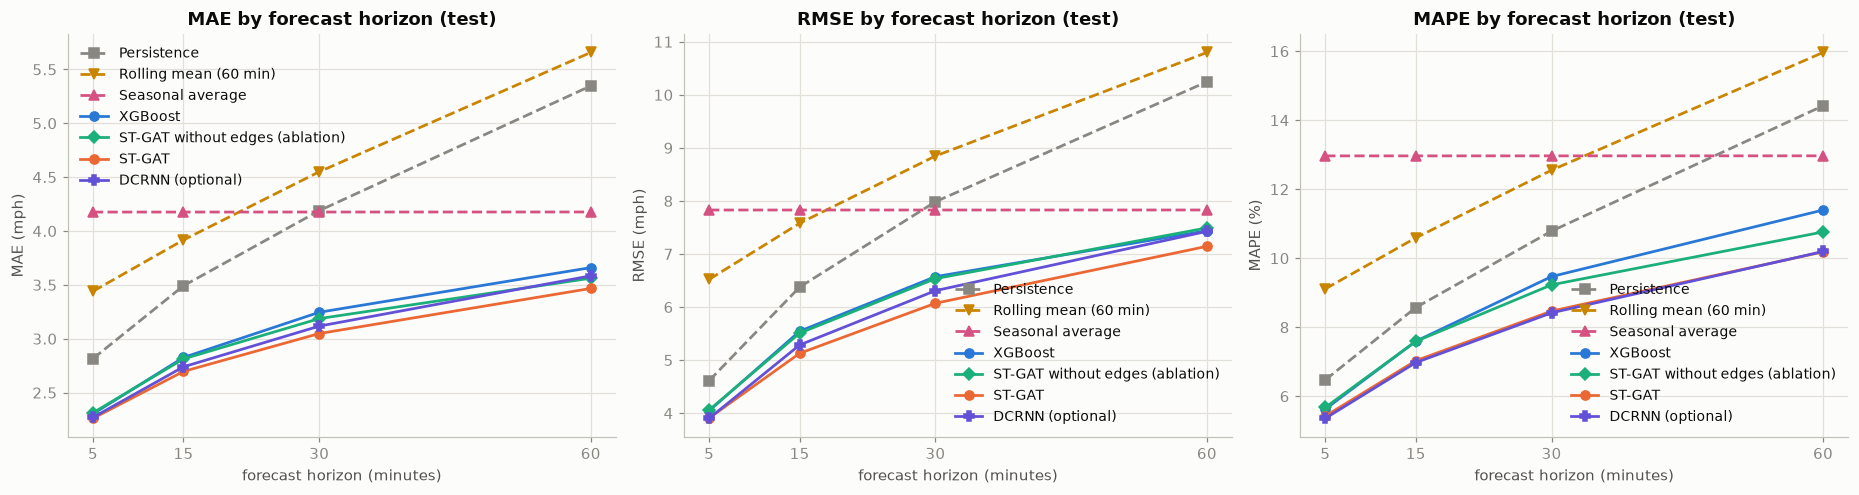

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, metric in zip(axes, ("MAE", "RMSE", "MAPE")):
    viz.plot_metric_vs_horizon(ax, table, metric, MODELS, title=f"{metric} by forecast horizon (test)")
fig.tight_layout(); viz.save_figure(fig, "07_metrics_vs_horizon"); plt.show()

**Reading the figure.** Every model's error grows with the horizon except the seasonal average, which is horizon-independent. The ordering of the
learned models relative to the baselines at each horizon is in the table above; the statistical comparison of the graph model with XGBoost follows.

## 4 · Does the graph help? Improvement of ST-GAT over XGBoost (and over its own no-edge ablation)

`improvement = 100 × (error_reference − error_ST-GAT) / error_reference`; **positive = ST-GAT has the lower error.**
The no-edge ablation is the cleanest test of the graph itself: identical architecture, parameter count and training recipe, edges removed.

In [8]:
target_time = ctx.timestamps.values[origins[:, None] + np.array(HZ)[None, :]]                 # [S, H]
day_index = ((pd.DatetimeIndex(target_time.ravel()).normalize() - pd.Timestamp(ctx.timestamps[ctx.splits.test[0]]).normalize()).days.to_numpy()).reshape(target_time.shape)

def improvement_with_ci(reference, candidate, metric="MAE"):
    rows = []
    for j, h in enumerate(HZ):
        out = ev.day_block_bootstrap_improvement(preds[reference][:, j], preds[candidate][:, j], y[:, j], valid[:, j], day_index[:, j], n_boot=2000, metric=metric)
        ref_m = table[(table.model == reference) & (table.horizon_steps == h)].iloc[0]; new_m = table[(table.model == candidate) & (table.horizon_steps == h)].iloc[0]
        rows.append({"horizon_min": h * 5, f"{metric} {reference}": ref_m[metric], f"{metric} {candidate}": new_m[metric], "improvement_%": out["improvement_pct"],
                     "95% CI low": out["ci_low"], "95% CI high": out["ci_high"], "bootstrap share > 0": out["share_boot_positive"]})
    return pd.DataFrame(rows).set_index("horizon_min")

comparisons = {}
if {"xgboost", "gat"} <= set(MODELS):
    comparisons["gat_vs_xgboost"] = ("xgboost", "gat")
if {"gat_nograph", "gat"} <= set(MODELS):
    comparisons["gat_vs_nograph"] = ("gat_nograph", "gat")
if {"persistence", "gat"} <= set(MODELS):
    comparisons["gat_vs_persistence"] = ("persistence", "gat")
if {"xgboost", "gat_nograph"} <= set(MODELS):
    comparisons["nograph_vs_xgboost"] = ("xgboost", "gat_nograph")
imp = {}
for name, (ref, cand) in comparisons.items():
    for metric in ("MAE", "RMSE"):
        imp[(name, metric)] = improvement_with_ci(ref, cand, metric)
        imp[(name, metric)].to_csv(config.METRICS_DIR / f"{config.tagged('improvement_' + name + '_' + metric.lower())}.csv")
    print(f"\n=== {labels[cand]} vs {labels[ref]}  (positive = {labels[cand]} better) ===")
    display(pd.concat({k: imp[(name, k)][["improvement_%", "95% CI low", "95% CI high"]] for k in ("MAE", "RMSE")}, axis=1).round(2))


=== ST-GAT vs XGBoost  (positive = ST-GAT better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                    1.79       1.57        2.01          3.36       3.03   
15                   4.58       4.11        5.08          7.51       6.68   
30                   6.09       5.30        6.78          7.63       6.50   
60                   5.28       4.42        6.10          3.95       2.83   

                         
            95% CI high  
horizon_min              
5                  3.71  
15                 8.30  
30                 8.63  
60                 5.04


=== ST-GAT vs ST-GAT without edges (ablation)  (positive = ST-GAT better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                    2.23       2.00        2.48          3.72       3.37   
15                   4.12       3.65        4.64          6.90       6.15   
30                   4.36       3.79        4.90          7.10       6.18   
60                   2.67       2.04        3.21          4.64       3.85   

                         
            95% CI high  
horizon_min              
5                  4.11  
15                 7.69  
30                 7.95  
60                 5.35


=== ST-GAT vs Persistence  (positive = ST-GAT better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                   19.69      19.20       20.11         15.26      14.63   
15                  22.76      22.06       23.38         19.57      18.34   
30                  27.23      25.92       28.39         23.97      22.06   
60                  35.16      32.99       36.94         30.27      27.63   

                         
            95% CI high  
horizon_min              
5                 15.80  
15                20.61  
30                25.63  
60                32.48


=== ST-GAT without edges (ablation) vs XGBoost  (positive = ST-GAT without edges (ablation) better) ===


MAE                                 RMSE             \
            improvement_% 95% CI low 95% CI high improvement_% 95% CI low   
horizon_min                                                                 
5                   -0.45      -0.59       -0.31         -0.37      -0.57   
15                   0.48       0.13        0.80          0.65       0.09   
30                   1.81       1.18        2.38          0.58      -0.23   
60                   2.68       1.90        3.41         -0.72      -1.73   

                         
            95% CI high  
horizon_min              
5                 -0.18  
15                 1.18  
30                 1.32  
60                 0.22

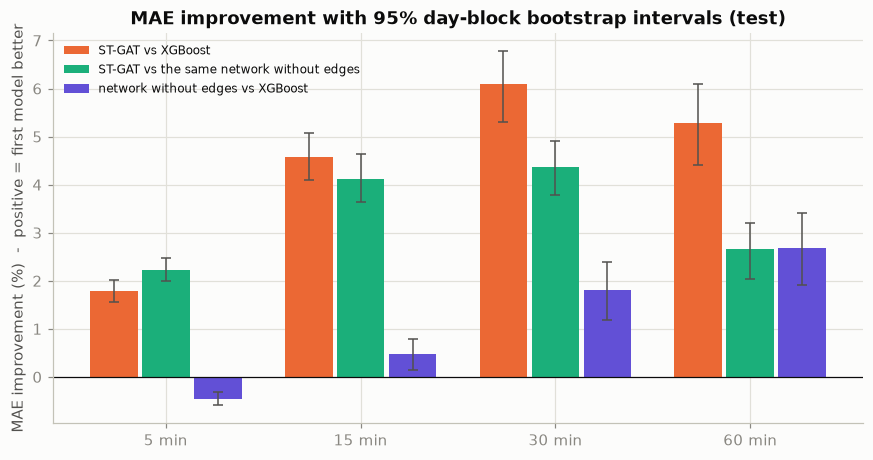

In [9]:
if comparisons:
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    names = [n for n in ("gat_vs_xgboost", "gat_vs_nograph", "nograph_vs_xgboost") if n in comparisons]
    colors = {"gat_vs_xgboost": "#eb6834", "gat_vs_nograph": "#1baf7a", "nograph_vs_xgboost": "#6250d6"}
    text = {"gat_vs_xgboost": "ST-GAT vs XGBoost", "gat_vs_nograph": "ST-GAT vs the same network without edges", "nograph_vs_xgboost": "network without edges vs XGBoost"}
    w = 0.8 / len(names)
    x = np.arange(len(HZ))
    for k, n in enumerate(names):
        d = imp[(n, "MAE")]
        ax.bar(x + (k - (len(names) - 1) / 2) * w, d["improvement_%"], width=w * 0.92, color=colors[n], label=text[n],
               yerr=[d["improvement_%"] - d["95% CI low"], d["95% CI high"] - d["improvement_%"]], error_kw=dict(ecolor=viz.INK_2, lw=1, capsize=3))
    ax.axhline(0, color=viz.INK, lw=0.8)
    ax.set_xticks(x, [f"{h * 5} min" for h in HZ]); ax.set_ylabel("MAE improvement (%)  -  positive = first model better")
    ax.set_title("MAE improvement with 95% day-block bootstrap intervals (test)"); ax.legend(fontsize=8)
    viz.save_figure(fig, "07_improvement_over_xgboost"); plt.show()
else:
    print("ST-GAT / XGBoost predictions missing: improvement analysis skipped")

In [10]:
# Machine-generated verdict (no hand-typed numbers)
verdict_lines = []
for name, (ref, cand) in comparisons.items():
    d = imp[(name, "MAE")]
    sig_better = [int(h) for h in d.index if d.loc[h, "95% CI low"] > 0]
    sig_worse = [int(h) for h in d.index if d.loc[h, "95% CI high"] < 0]
    inconclusive = [int(h) for h in d.index if d.loc[h, "95% CI low"] <= 0 <= d.loc[h, "95% CI high"]]
    fmt = lambda hs: (", ".join(map(str, hs)) + " min") if hs else "none of the horizons"
    verdict_lines.append(f"{labels[cand]} vs {labels[ref]} (MAE): clearly better at {fmt(sig_better)}; clearly worse at {fmt(sig_worse)}; "
                         f"inconclusive at {fmt(inconclusive)} (95% day-block bootstrap, single training run).")
print("\n".join(verdict_lines))

ST-GAT vs XGBoost (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT vs ST-GAT without edges (ablation) (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT vs Persistence (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT without edges (ablation) vs XGBoost (MAE): clearly better at 15, 30, 60 min; clearly worse at 5 min; inconclusive at none of the horizons (95% day-block bootstrap, single training run).


**Reading the results.** A horizon counts as "clearly better" only if the whole 95% interval is above zero. The bootstrap accounts for day-to-day variation in the 24
test days but **not** for differences between training runs: the models were trained once (one seed) unless the extra-seed experiment in section 9 was run.
The comparison with the same network *without* edges isolates the effect of the road graph; the comparison with XGBoost mixes the graph effect with the
effect of the different model family (recurrent network vs trees).

## 5 · Peak versus off-peak

In [11]:
peak = ev.peak_flags_sh(ctx.timestamps, origins, HZ)                       # [S, H], by forecast target time
groups = {"peak": peak, "off-peak": ~peak}
print(f"definition: weekday hours {config.PEAK_WINDOWS} local time of the forecast target (fixed before any model was evaluated)")
grp = ev.metrics_by_group({m: preds[m] for m in MODELS}, y, valid, HZ, groups)
grp.to_csv(config.METRICS_DIR / f"{config.tagged('test_metrics_peak_offpeak')}.csv", index=False)
share = {g: float((valid & f[:, :, None]).sum() / valid.sum()) for g, f in groups.items()}
print("share of valid test points:", {k: f"{v:.1%}" for k, v in share.items()})
view = grp.assign(order=grp["model"].map({m: i for i, m in enumerate(MODELS)}), model=grp["model"].map(labels))
view = view.pivot_table(index=["group", "order", "model"], columns="horizon_min", values=["MAE", "RMSE"]).droplevel("order")
display(view.round(2))

definition: weekday hours ((7, 10), (15, 19)) local time of the forecast target (fixed before any model was evaluated)


share of valid test points: {'peak': '23.3%', 'off-peak': '76.7%'}


MAE                     RMSE  \
horizon_min                                 5     15    30    60     5    
group    model                                                            
off-peak Persistence                      2.66  3.16  3.69  4.62   4.30   
         Rolling mean (60 min)            2.99  3.37  3.88  4.83   5.71   
         Seasonal average                 3.46  3.46  3.46  3.46   6.74   
         XGBoost                          2.11  2.48  2.76  3.05   3.66   
         ST-GAT without edges (ablation)  2.12  2.47  2.74  2.99   3.68   
         ST-GAT                           2.09  2.39  2.64  2.93   3.57   
         DCRNN (optional)                 2.10  2.42  2.68  3.02   3.56   
peak     Persistence                      3.31  4.59  5.82  7.74   5.51   
         Rolling mean (60 min)            4.91  5.73  6.76  8.39   8.67   
         Seasonal average                 6.52  6.52  6.52  6.52  10.65   
         XGBoost                          2.92  3.98  4.83  5.67   5.11   
         ST-GAT without edges (ablation)  2.94  3.94  4.67  5.43   5.12   
         ST-GAT                           2.83  3.70  4.38  5.23   4.85   
         DCRNN (optional)                 2.84  3.79  4.55  5.43   4.85   

                                                               
horizon_min                                  15     30     60  
group    model                                                 
off-peak Persistence                       5.69   7.04   8.99  
         Rolling mean (60 min)             6.61   7.70   9.45  
         Seasonal average                  6.74   6.74   6.74  
         XGBoost                           4.81   5.61   6.35  
         ST-GAT without edges (ablation)   4.80   5.66   6.43  
         ST-GAT                            4.53   5.31   6.17  
         DCRNN (optional)                  4.62   5.44   6.35  
peak     Persistence                       8.24  10.51  13.58  
         Rolling mean (60 min)            10.14  11.86  14.37  
         Seasonal average                 10.65  10.65  10.65  
         XGBoost                           7.47   9.05  10.24  
         ST-GAT without edges (ablation)   7.36   8.82  10.23  
         ST-GAT                            6.74   8.09   9.68  
         DCRNN (optional)                  7.03   8.57  10.19

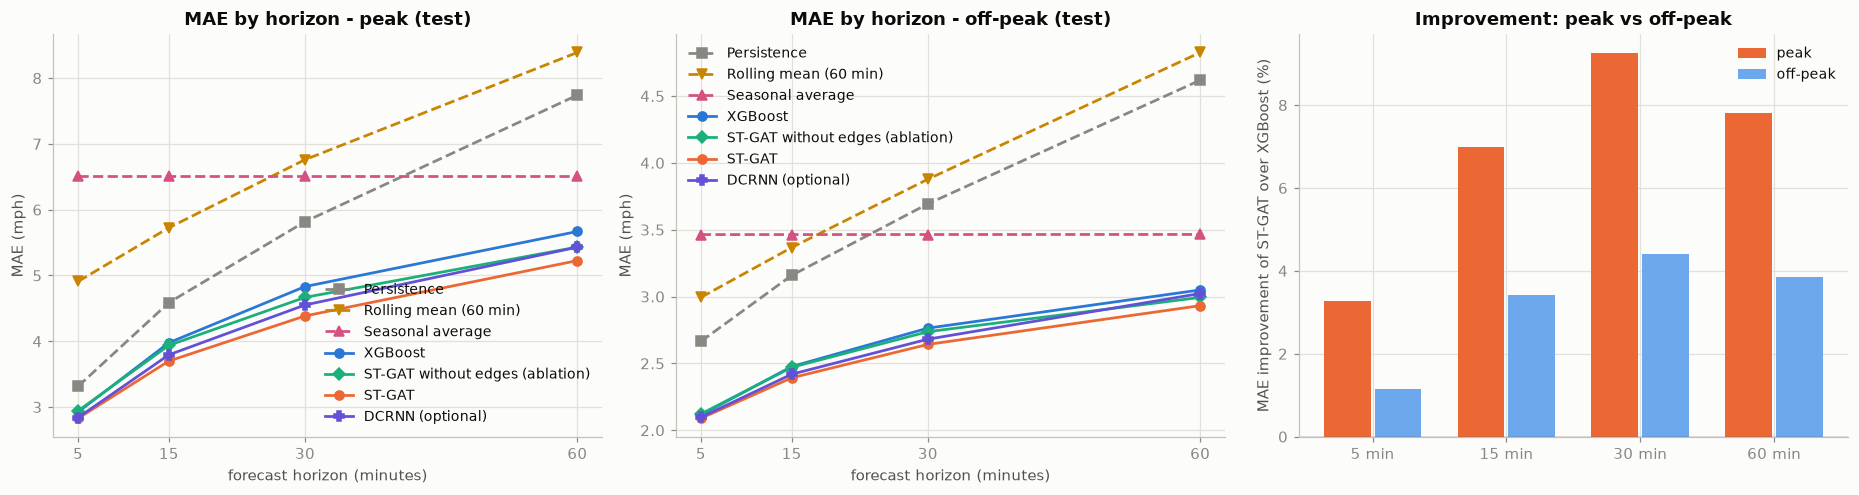

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, g in zip(axes[:2], ("peak", "off-peak")):
    viz.plot_metric_vs_horizon(ax, grp[grp.group == g], "MAE", MODELS, title=f"MAE by horizon - {g} (test)")
if {"xgboost", "gat"} <= set(MODELS):
    xs = np.arange(len(HZ)); w = 0.38
    for k, g in enumerate(("peak", "off-peak")):
        sub = grp[grp.group == g]
        ref = sub[sub.model == "xgboost"].sort_values("horizon_steps")["MAE"].to_numpy(); new = sub[sub.model == "gat"].sort_values("horizon_steps")["MAE"].to_numpy()
        axes[2].bar(xs + (k - 0.5) * w, 100 * (ref - new) / ref, width=w * 0.92, color=["#eb6834", "#6da7ec"][k], label=g)
    axes[2].axhline(0, color=viz.INK, lw=0.8); axes[2].set_xticks(xs, [f"{h * 5} min" for h in HZ])
    axes[2].set_ylabel("MAE improvement of ST-GAT over XGBoost (%)"); axes[2].set_title("Improvement: peak vs off-peak"); axes[2].legend()
fig.tight_layout(); viz.save_figure(fig, "07_peak_vs_offpeak"); plt.show()

In [13]:
if {"xgboost", "gat"} <= set(MODELS):
    rows = []
    for g, flag in groups.items():
        for j, h in enumerate(HZ):
            sel_valid = valid[:, j] & flag[:, j, None]
            sel_days = day_index[:, j]
            out = ev.day_block_bootstrap_improvement(preds["xgboost"][:, j], preds["gat"][:, j], y[:, j], sel_valid, sel_days, n_boot=1000)
            rows.append({"group": g, "horizon_min": h * 5, "improvement_%": out["improvement_pct"], "95% CI low": out["ci_low"], "95% CI high": out["ci_high"]})
    peak_imp = pd.DataFrame(rows)
    peak_imp.to_csv(config.METRICS_DIR / f"{config.tagged('improvement_peak_offpeak')}.csv", index=False)
    display(peak_imp.pivot(index="group", columns="horizon_min", values=["improvement_%", "95% CI low", "95% CI high"]).round(2))

improvement_%                   95% CI low                    \
horizon_min            5     15    30    60         5     15    30    60   
group                                                                      
off-peak             1.16  3.41  4.40  3.85       1.00  3.01  3.67  2.95   
peak                 3.28  6.99  9.25  7.81       2.96  6.31  8.34  6.64   

            95% CI high                     
horizon_min          5     15     30    60  
group                                       
off-peak           1.33  3.85   5.23  4.86  
peak               3.61  7.64  10.15  9.03

## 6 · Sensor-level analysis (where does the graph help?)

For each sensor we compare the ST-GAT with XGBoost on the test period. We then ask whether the per-sensor difference is related to
(a) the sensor's **graph degree** (in + out neighbours), (b) its **missing-data share** in the test period, and (c) its **historical variability**
(standard deviation of its *training* speeds). Relations are reported as Spearman rank correlations; they are descriptive, not causal.

In [14]:
if {"xgboost", "gat"} <= set(MODELS):
    per = {m: ev.per_sensor_metrics(preds[m], y, valid, HZ, ctx.sensor_ids) for m in ("xgboost", "gat")}
    deg = gu.graph_stats(graph.adjacency)
    a, b = ctx.splits.train
    tr_obs = ctx.mask[a:b]; tr_std = np.sqrt(np.where(tr_obs, (ctx.speed[a:b] - ctx.scaler.sensor_mean) ** 2, 0).sum(0) / np.maximum(tr_obs.sum(0), 1))
    t0, t1 = ctx.splits.test
    info = pd.DataFrame({"node": np.arange(N), "sensor_id": ctx.sensor_ids, "degree_total": deg["in_degree"] + deg["out_degree"],
                         "test_missing_%": 100 * (~ctx.mask[t0:t1]).mean(0), "train_speed_std": tr_std}).set_index("node")
    sensor_tables = {}
    for h in HZ:
        a_ = per["xgboost"][per["xgboost"].horizon_steps == h].set_index("node"); g_ = per["gat"][per["gat"].horizon_steps == h].set_index("node")
        t = info.copy(); t["MAE_xgboost"] = a_["MAE"]; t["MAE_gat"] = g_["MAE"]
        t["improvement_%"] = 100 * (t["MAE_xgboost"] - t["MAE_gat"]) / t["MAE_xgboost"]
        sensor_tables[h] = t
    pd.concat({h * 5: t for h, t in sensor_tables.items()}, names=["horizon_min"]).to_csv(config.METRICS_DIR / f"{config.tagged('sensor_level_improvement')}.csv")
    rows = []
    for h, t in sensor_tables.items():
        rows.append({"horizon_min": h * 5, "sensors where ST-GAT is better": int((t["improvement_%"] > 0).sum()), "sensors where it is worse": int((t["improvement_%"] < 0).sum()),
                     "median improvement_%": t["improvement_%"].median(), "10th pct": t["improvement_%"].quantile(.1), "90th pct": t["improvement_%"].quantile(.9)})
    display(pd.DataFrame(rows).set_index("horizon_min").round(2))

,sensors where ST-GAT is better,sensors where it is worse,median improvement_%,10th pct,90th pct
horizon_min,,,,,
5,146,61,0.93,-0.83,4.67
15,176,31,3.26,-0.34,9.00
30,181,26,4.76,-0.21,11.81
60,156,51,3.20,-1.31,12.53


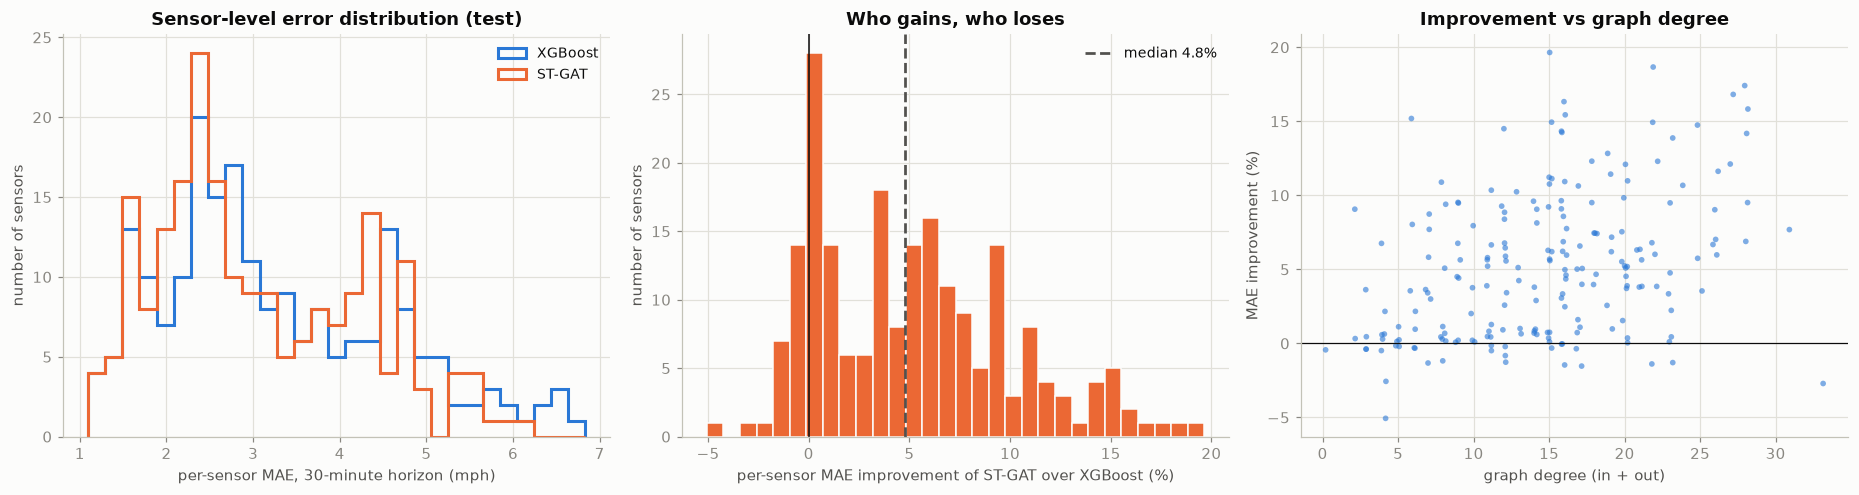

horizon_min,5,15,30,60
sensor property,,,,
graph degree,0.30,0.37,0.37,0.32
historical variability,0.51,0.59,0.66,0.65
test-period missing %,-0.06,-0.12,-0.15,-0.13


the sensor properties are themselves correlated (Spearman) - the single correlations above are confounded with each other:


,degree_total,test_missing_%,train_speed_std
degree_total,1.00,-0.12,0.31
test_missing_%,-0.12,1.00,0.04
train_speed_std,0.31,0.04,1.00



30-minute horizon - sensors where ST-GAT helps MOST:


,sensor_id,degree_total,test_missing_%,train_speed_std,MAE_xgboost,MAE_gat,improvement_%
node,,,,,,,
79,718066,16,9.64,10.21,2.34,1.96,16.33
163,717462,27,9.68,23.61,6.61,5.50,16.81
160,717461,28,19.47,22.47,6.11,5.05,17.41
127,717472,22,13.28,20.52,5.87,4.78,18.66
199,774204,15,9.64,13.39,3.82,3.07,19.65


30-minute horizon - sensors where ST-GAT performs WORST relative to XGBoost:


,sensor_id,degree_total,test_missing_%,train_speed_std,MAE_xgboost,MAE_gat,improvement_%
node,,,,,,,
90,716571,4,11.33,3.37,1.38,1.45,-5.06
16,771667,33,19.70,5.64,1.74,1.78,-2.71
194,759772,4,10.45,8.24,3.72,3.82,-2.56
168,717583,17,9.64,5.96,2.42,2.46,-1.53
40,768066,16,9.92,11.62,2.23,2.26,-1.46


isolated sensor(s) in the road graph (no neighbours to use):


,sensor_id,MAE_xgboost,MAE_gat,improvement_%
node,,,,
26,717804,4.4,4.42,-0.44


In [15]:
if {"xgboost", "gat"} <= set(MODELS):
    jh = 6 if 6 in HZ else HZ[len(HZ) // 2]
    t = sensor_tables[jh]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    # (a) distribution of per-sensor MAE of both models
    bins = np.linspace(min(t["MAE_xgboost"].min(), t["MAE_gat"].min()), max(t["MAE_xgboost"].max(), t["MAE_gat"].max()), 30)
    for m, col in (("xgboost", "MAE_xgboost"), ("gat", "MAE_gat")):
        axes[0].hist(t[col], bins=bins, histtype="step", lw=2, color=viz.style(m)["color"], label=viz.style(m)["label"])
    axes[0].set_xlabel(f"per-sensor MAE, {jh * 5}-minute horizon (mph)"); axes[0].set_ylabel("number of sensors"); axes[0].set_title("Sensor-level error distribution (test)"); axes[0].legend()
    # (b) per-sensor improvement distribution
    axes[1].hist(t["improvement_%"], bins=30, color="#eb6834", edgecolor=viz.SURFACE)
    axes[1].axvline(0, color=viz.INK, lw=1); axes[1].axvline(t["improvement_%"].median(), color=viz.INK_2, ls="--", label=f"median {t['improvement_%'].median():.1f}%")
    axes[1].set_xlabel("per-sensor MAE improvement of ST-GAT over XGBoost (%)"); axes[1].set_ylabel("number of sensors"); axes[1].set_title("Who gains, who loses"); axes[1].legend()
    # (c) improvement vs degree
    axes[2].scatter(t["degree_total"] + np.random.default_rng(0).uniform(-0.2, 0.2, len(t)), t["improvement_%"], s=14, alpha=0.6, color="#2a78d6", edgecolor="none")
    axes[2].axhline(0, color=viz.INK, lw=0.8); axes[2].set_xlabel("graph degree (in + out)"); axes[2].set_ylabel("MAE improvement (%)"); axes[2].set_title("Improvement vs graph degree")
    fig.tight_layout(); viz.save_figure(fig, "07_sensor_level"); plt.show()

    rows = []
    for h, tt in sensor_tables.items():
        for col, name in (("degree_total", "graph degree"), ("test_missing_%", "test-period missing %"), ("train_speed_std", "historical variability")):
            rho, p = stats.spearmanr(tt[col], tt["improvement_%"])
            rows.append({"horizon_min": h * 5, "sensor property": name, "Spearman rho": rho, "p-value": p})
    corr = pd.DataFrame(rows)
    display(corr.pivot(index="sensor property", columns="horizon_min", values="Spearman rho").round(2))
    props = sensor_tables[HZ[0]][["degree_total", "test_missing_%", "train_speed_std"]]
    print("the sensor properties are themselves correlated (Spearman) - the single correlations above are confounded with each other:")
    display(props.corr(method="spearman").round(2))
    corr.to_csv(config.METRICS_DIR / f"{config.tagged('sensor_level_correlations')}.csv", index=False)
    top = t.sort_values("improvement_%")
    print(f"\n{jh * 5}-minute horizon - sensors where ST-GAT helps MOST:"); display(top.tail(5)[["sensor_id", "degree_total", "test_missing_%", "train_speed_std", "MAE_xgboost", "MAE_gat", "improvement_%"]].round(2))
    print(f"{jh * 5}-minute horizon - sensors where ST-GAT performs WORST relative to XGBoost:"); display(top.head(5)[["sensor_id", "degree_total", "test_missing_%", "train_speed_std", "MAE_xgboost", "MAE_gat", "improvement_%"]].round(2))
    iso = [i for i in deg["isolated_nodes"]]
    if iso:
        print("isolated sensor(s) in the road graph (no neighbours to use):"); display(t.loc[iso, ["sensor_id", "MAE_xgboost", "MAE_gat", "improvement_%"]].round(2))

In [16]:
# degree buckets (terciles of the graph degree), mean improvement
if {"xgboost", "gat"} <= set(MODELS):
    rows = []
    for h, tt in sensor_tables.items():
        buckets = pd.qcut(tt["degree_total"].rank(method="first"), 3, labels=["low degree", "mid degree", "high degree"])
        for b, g in tt.groupby(buckets, observed=True):
            rows.append({"horizon_min": h * 5, "degree group": b, "degree range": f"{int(g.degree_total.min())}-{int(g.degree_total.max())}", "median improvement_%": g["improvement_%"].median()})
    display(pd.DataFrame(rows).pivot(index=["degree group", "degree range"], columns="horizon_min", values="median improvement_%").round(2))

,horizon_min,5,15,30,60
degree group,degree range,,,,
high degree,17-33,2.11,5.16,6.19,4.61
low degree,0-12,0.36,1.24,1.12,0.70
mid degree,12-17,1.00,4.28,5.59,4.19


**Reading the sensor-level results.** The tables count how many sensors benefit, how large the spread is, and whether the benefit correlates with
how connected, how incomplete or how variable a sensor is. With 207 sensors a Spearman |rho| below roughly 0.14 is not distinguishable from zero at the
5% level; the reported p-values should be read with that in mind, and none of this establishes a causal mechanism.

## 7 · Selected actual-versus-predicted time series (test)

Two representative sensors (rule fixed on **training** statistics) on a test weekday, at the 15- and 60-minute horizons. Gaps in the black line are missing observations.

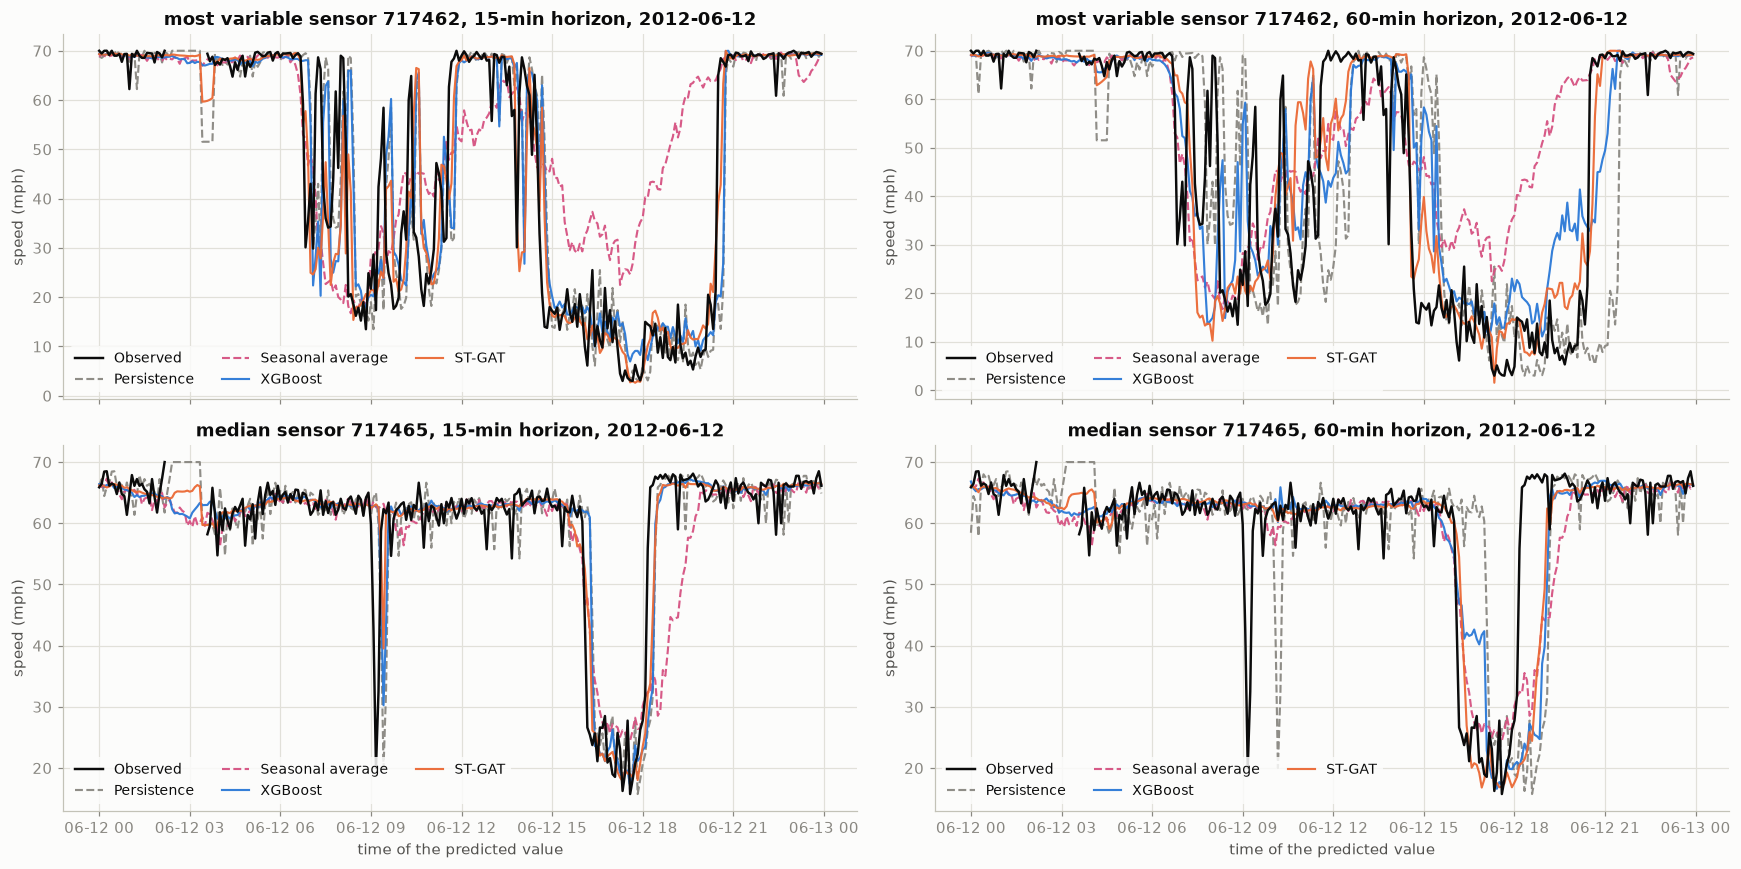

In [17]:
rep = ev.select_representative_sensors(ctx.speed, ctx.mask, ctx.splits.train, ctx.sensor_ids)
show = [m for m in ("persistence", "seasonal_avg", "xgboost", "gat") if m in MODELS]
day = pd.Timestamp("2012-06-12")                                           # a Tuesday in the test period
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True)
for col, hz in enumerate((3, 12)):
    j = HZ.index(hz); tt = ctx.timestamps[origins + hz]
    sel = np.flatnonzero((tt >= day) & (tt < day + pd.Timedelta(days=1)))
    for row, key in enumerate(("most_variable", "median")):
        n = rep[key]
        viz.plot_actual_vs_predicted(axes[row, col], tt[sel], y[sel, j, n], {m: preds[m][sel, j, n] for m in show},
                                     f"{key.replace('_', ' ')} sensor {ctx.sensor_ids[n]}, {hz * 5}-min horizon, {day.date()}")
for ax in axes[-1]:
    ax.set_xlabel("time of the predicted value")
fig.tight_layout(); viz.save_figure(fig, "07_actual_vs_predicted"); plt.show()

## 8 · Overall picture across all horizons (average over the four horizons)

In [18]:
avg = table.groupby("model")[["MAE", "RMSE", "MAPE"]].mean().reindex(MODELS)
avg.index = [labels[m] for m in avg.index]
display(avg.round(2).sort_values("MAE"))

,MAE,RMSE,MAPE
ST-GAT,2.87,5.56,7.78
DCRNN (optional),2.93,5.73,7.74
ST-GAT without edges (ablation),2.97,5.90,8.31
XGBoost,3.01,5.90,8.52
Persistence,3.96,7.30,10.06
Seasonal average,4.18,7.83,12.97
Rolling mean (60 min),4.39,8.44,12.05


## 9 · Seed robustness (only if extra seeds were trained in notebook 06)

In [19]:
seed_keys = {base: [base] + sorted(p.name.split("__")[0].replace(config.tagged(""), "") for p in config.PREDICTIONS_DIR.glob(f"{config.tagged(base + '_seed')}*__test.npz")) for base in ("gat", "gat_nograph")}
rows = []
for base, keys in seed_keys.items():
    for k in keys:
        try:
            d = ev.load_predictions(k, "test")
        except FileNotFoundError:
            continue
        for j, h in enumerate(HZ):
            rows.append({"model": base, "run": k, "horizon_min": h * 5, "MAE": compute_metrics(d["pred"][:, j], y[:, j], valid[:, j])["MAE"]})
seed_table = pd.DataFrame(rows)
if seed_table.groupby("model")["run"].nunique().max() > 1:
    summary = seed_table.groupby(["model", "horizon_min"])["MAE"].agg(["mean", "std", "min", "max", "count"])
    display(summary.round(3)); seed_table.to_csv(config.METRICS_DIR / f"{config.tagged('seed_robustness')}.csv", index=False)
    # paired by seed: improvement of each ST-GAT run over (a) the single XGBoost model and (b) the no-edge run with the SAME seed
    xgb_mae = table[table.model == "xgboost"].set_index("horizon_min")["MAE"] if "xgboost" in MODELS else None
    rows = []
    for k in seed_keys["gat"]:
        if k not in set(seed_table.run):
            continue
        twin = k.replace("gat", "gat_nograph", 1)
        for h in HZ:
            g = seed_table[(seed_table.run == k) & (seed_table.horizon_min == h * 5)]["MAE"].iloc[0]
            n_ = seed_table[(seed_table.run == twin) & (seed_table.horizon_min == h * 5)]["MAE"]
            rows.append({"run": k, "horizon_min": h * 5, "MAE ST-GAT": g,
                         "improvement over XGBoost %": improvement_pct(xgb_mae[h * 5], g) if xgb_mae is not None else np.nan,
                         "improvement over same-seed no-edge %": improvement_pct(n_.iloc[0], g) if len(n_) else np.nan})
    paired = pd.DataFrame(rows)
    display(paired.pivot(index="run", columns="horizon_min", values="improvement over XGBoost %").round(2).rename_axis("ST-GAT improvement over XGBoost (%), by seed"))
    display(paired.pivot(index="run", columns="horizon_min", values="improvement over same-seed no-edge %").round(2).rename_axis("ST-GAT improvement over the no-edge network of the same seed (%)"))
    paired.to_csv(config.METRICS_DIR / f"{config.tagged('seed_paired_improvements')}.csv", index=False)
    seed_claims = {
        "[seeds] every ST-GAT seed beats XGBoost in MAE at every horizon": bool((paired["improvement over XGBoost %"] > 0).all()),
        "[seeds] every ST-GAT seed beats the no-edge network of the same seed at every horizon": bool((paired["improvement over same-seed no-edge %"] > 0).all()),
        "[seeds] the seed-to-seed std of ST-GAT test MAE is below 0.05 mph at every horizon": bool((summary.loc["gat", "std"] < 0.05).all()),
        "[seeds] the smallest per-seed gain over the no-edge network exceeds the largest MAE std of either model": bool(paired["improvement over same-seed no-edge %"].min() / 100 * summary.loc["gat", "mean"].min() > summary["std"].max()),
    }
    display(ev.report_claims(seed_claims))
else:
    seed_claims = {}
    print("only one training run per model is available: seed-to-seed variability was NOT measured; treat small differences between models with caution.")

mean    std    min    max  count
model       horizon_min                                   
gat         5            2.261  0.004  2.257  2.265      3
            15           2.695  0.004  2.690  2.697      3
            30           3.045  0.009  3.035  3.052      3
            60           3.464  0.012  3.450  3.474      3
gat_nograph 5            2.318  0.005  2.313  2.323      3
            15           2.820  0.009  2.813  2.830      3
            30           3.191  0.004  3.187  3.194      3
            60           3.571  0.008  3.562  3.577      3

horizon_min,5,15,30,60
"ST-GAT improvement over XGBoost (%), by seed",,,,
gat,1.79,4.58,6.09,5.28
gat_seed1,1.64,4.57,5.96,5.10
gat_seed2,1.97,4.81,6.51,5.74


horizon_min,5,15,30,60
ST-GAT improvement over the no-edge network of the same seed (%),,,,
gat,2.23,4.12,4.36,2.67
gat_seed1,2.30,4.30,4.44,2.90
gat_seed2,2.83,4.92,4.89,3.43


,claim,holds in this run
0,[seeds] every ST-GAT seed beats XGBoost in MAE...,True
1,[seeds] every ST-GAT seed beats the no-edge ne...,True
2,[seeds] the seed-to-seed std of ST-GAT test MA...,True
3,[seeds] the smallest per-seed gain over the no...,True


In [20]:
SEED_TEXT = "**Seed robustness** (three training runs, seeds 42, 1 and 2, for both the ST-GAT and its no-edge twin; XGBoost is deterministic and was fitted once).\n\n* The ST-GAT's test MAE varies by only about a hundredth of a mph between seeds, far less than its gap to XGBoost or to the no-edge network.\n* **Every** seed beats XGBoost at every horizon and beats the no-edge network trained with the same seed at every horizon, so the graph effect reported above is not an accident of one initialisation.\n* Three seeds is still a small sample; it shows the effect is stable, not a precise estimate of its size."
from IPython.display import Markdown
if seed_claims and all(seed_claims.values()):
    display(Markdown(SEED_TEXT))
elif seed_claims:
    print("some seed claims do not hold in this run: read the seed tables directly")

**Seed robustness** (three training runs, seeds 42, 1 and 2, for both the ST-GAT and its no-edge twin; XGBoost is deterministic and was fitted once).

* The ST-GAT's test MAE varies by only about a hundredth of a mph between seeds, far less than its gap to XGBoost or to the no-edge network.
* **Every** seed beats XGBoost at every horizon and beats the no-edge network trained with the same seed at every horizon, so the graph effect reported above is not an accident of one initialisation.
* Three seeds is still a small sample; it shows the effect is stable, not a precise estimate of its size.

## 10 · Final comparison summary (generated from the tables)

In [21]:
lines = []
for j, h in enumerate(HZ):
    row = table[table.horizon_steps == h].set_index("model")["MAE"]
    order = [labels[m] for m in row.sort_values().index]
    lines.append(f"{h * 5:>2d} min: " + " < ".join(f"{labels[m]} {row[m]:.2f}" for m in row.sort_values().index))
print("Test MAE ranking per horizon (lower is better):"); print("\n".join(lines))
print()
print("\n".join(verdict_lines))
if config.IS_SMOKE:
    print("\n*** SMOKE RUN: not final results ***")

Test MAE ranking per horizon (lower is better):
 5 min: ST-GAT 2.26 < DCRNN (optional) 2.27 < XGBoost 2.30 < ST-GAT without edges (ablation) 2.31 < Persistence 2.82 < Rolling mean (60 min) 3.44 < Seasonal average 4.18
15 min: ST-GAT 2.70 < DCRNN (optional) 2.74 < ST-GAT without edges (ablation) 2.81 < XGBoost 2.83 < Persistence 3.49 < Rolling mean (60 min) 3.92 < Seasonal average 4.18
30 min: ST-GAT 3.05 < DCRNN (optional) 3.12 < ST-GAT without edges (ablation) 3.19 < XGBoost 3.25 < Seasonal average 4.18 < Persistence 4.19 < Rolling mean (60 min) 4.55
60 min: ST-GAT 3.47 < ST-GAT without edges (ablation) 3.56 < DCRNN (optional) 3.58 < XGBoost 3.66 < Seasonal average 4.18 < Persistence 5.35 < Rolling mean (60 min) 5.66

ST-GAT vs XGBoost (MAE): clearly better at 5, 15, 30, 60 min; clearly worse at none of the horizons; inconclusive at none of the horizons (95% day-block bootstrap, single training run).
ST-GAT vs ST-GAT without edges (ablation) (MAE): clearly better at 5, 15, 30, 60 min;

## 10b · Findings (claims checked against this run)

The statements in the next cell are the ones the interpretation below relies on. A warning is printed if any of them does not hold in your run (for example after retraining with another seed).

In [22]:
claims = {}
edge_share = None
if {"gat", "gat_nograph", "xgboost"} <= set(MODELS):
    edge_share = (imp[("gat_vs_nograph", "MAE")]["improvement_%"] / imp[("gat_vs_xgboost", "MAE")]["improvement_%"]).rename("graph-edge share of the ST-GAT gain over XGBoost")
    claims["the edge-attributable share of the gain over XGBoost shrinks with the horizon"] = bool(edge_share.is_monotonic_decreasing)
if {"xgboost", "gat"} <= set(MODELS):
    ix = imp[("gat_vs_xgboost", "MAE")]
    claims["ST-GAT has the lowest test MAE of all models at every horizon"] = bool((best["model"] == labels["gat"]).all())
    claims["ST-GAT beats XGBoost at every horizon (95% interval entirely above 0)"] = bool((ix["95% CI low"] > 0).all())
    claims["ST-GAT's gain over XGBoost is smallest at the 5-minute horizon"] = bool(ix["improvement_%"].idxmin() == 5)
    claims["the absolute MAE gap to XGBoost never exceeds 0.3 mph"] = bool(((table[table.model == "xgboost"].set_index("horizon_min")["MAE"] - table[table.model == "gat"].set_index("horizon_min")["MAE"]).abs() < 0.3).all())
if {"gat_nograph", "gat"} <= set(MODELS):
    ig = imp[("gat_vs_nograph", "MAE")]
    claims["ST-GAT beats its own no-edge ablation at every horizon (95% interval entirely above 0)"] = bool((ig["95% CI low"] > 0).all())
if {"gat_nograph", "xgboost"} <= set(MODELS):
    inx = imp[("nograph_vs_xgboost", "MAE")]
    claims["the no-edge network is within 3.5% (MAE) of XGBoost at every horizon, i.e. roughly on par"] = bool((inx["improvement_%"].abs() < 3.5).all())
if "peak_imp" in globals():
    p_, o_ = peak_imp[peak_imp.group == "peak"].set_index("horizon_min"), peak_imp[peak_imp.group == "off-peak"].set_index("horizon_min")
    claims["ST-GAT's gain over XGBoost is larger at peak than off-peak at every horizon (intervals do not overlap)"] = bool((p_["95% CI low"] > o_["95% CI high"]).all())
if "sensor_tables" in globals():
    claims["ST-GAT has the lower MAE than XGBoost at a clear majority (> 60%) of sensors at every horizon"] = bool(all((tt["improvement_%"] > 0).mean() > 0.6 for tt in sensor_tables.values()))
    claims["the per-sensor gain correlates positively with historical variability (rho > 0.3 at every horizon)"] = bool((corr[corr["sensor property"] == "historical variability"]["Spearman rho"] > 0.3).all())
    claims["the per-sensor gain correlates positively with graph degree (rho > 0.2 at every horizon)"] = bool((corr[corr["sensor property"] == "graph degree"]["Spearman rho"] > 0.2).all())
if {"dcrnn", "gat", "xgboost", "gat_nograph"} <= set(MODELS):
    mae_ = table.pivot(index="horizon_min", columns="model", values="MAE"); rmse_ = table.pivot(index="horizon_min", columns="model", values="RMSE"); mape_ = table.pivot(index="horizon_min", columns="model", values="MAPE")
    claims["[DCRNN] the DCRNN-style graph model also beats XGBoost in MAE at every horizon"] = bool((mae_["dcrnn"] < mae_["xgboost"]).all())
    claims["[DCRNN] ST-GAT has the lower MAE than the DCRNN-style model at every horizon"] = bool((mae_["gat"] < mae_["dcrnn"]).all())
    claims["[DCRNN] the DCRNN-style MAE is within 5% of the ST-GAT's at every horizon"] = bool(((mae_["dcrnn"] / mae_["gat"] - 1).abs() < 0.05).all())
    claims["[DCRNN] the DCRNN-style model has lower MAPE than ST-GAT at 5, 15 and 30 min"] = bool((mape_.loc[[5, 15, 30], "dcrnn"] < mape_.loc[[5, 15, 30], "gat"]).all())
    claims["[DCRNN] the DCRNN-style model has slightly lower RMSE than ST-GAT at 5 min only"] = bool(rmse_.loc[5, "dcrnn"] < rmse_.loc[5, "gat"] and (rmse_.loc[[15, 30, 60], "dcrnn"] > rmse_.loc[[15, 30, 60], "gat"]).all())
    claims["[DCRNN] at 60 min it is within 1% of the no-edge network (no gain from its graph there)"] = bool(abs(mae_.loc[60, "dcrnn"] / mae_.loc[60, "gat_nograph"] - 1) < 0.01)
display(ev.report_claims(claims))
if edge_share is not None:
    print("ratio of (ST-GAT vs no-edge) to (ST-GAT vs XGBoost) improvement, per horizon - a descriptive ratio of two single-seed estimates, not a variance decomposition:")
    display(edge_share.round(2).to_frame())

,claim,holds in this run
0,the edge-attributable share of the gain over X...,True
1,ST-GAT has the lowest test MAE of all models a...,True
2,ST-GAT beats XGBoost at every horizon (95% int...,True
3,ST-GAT's gain over XGBoost is smallest at the ...,True
4,the absolute MAE gap to XGBoost never exceeds ...,True
5,ST-GAT beats its own no-edge ablation at every...,True
6,the no-edge network is within 3.5% (MAE) of XG...,True
7,ST-GAT's gain over XGBoost is larger at peak t...,True
8,ST-GAT has the lower MAE than XGBoost at a cle...,True
9,the per-sensor gain correlates positively with...,True


ratio of (ST-GAT vs no-edge) to (ST-GAT vs XGBoost) improvement, per horizon - a descriptive ratio of two single-seed estimates, not a variance decomposition:


,graph-edge share of the ST-GAT gain over XGBoost
horizon_min,
5,1.25
15,0.90
30,0.72
60,0.51


**Findings (for the delivered run: one training run per neural model, 24 test days).**

1. **Model ranking (main experiment).** Among the baselines, XGBoost, the ST-GAT and its no-edge ablation, the ST-GAT has the lowest test MAE at every horizon, followed by XGBoost and the no-edge network, which are close to each other. All three learned models beat persistence clearly; the seasonal average only beats persistence at long horizons. In absolute terms the ST-GAT's advantage over XGBoost is small: a few hundredths to about two tenths of a mph of MAE, i.e. a few percent.
2. **Does the graph help?** Within the same architecture, parameter count and training recipe, restricting attention to the sensor itself (no edges) is clearly worse than letting it use its road-graph neighbours, at every horizon, with intervals above zero. The no-edge network is roughly on par with XGBoost. Together this suggests that most of the ST-GAT's advantage over the independent-sensor models is associated with using the neighbouring sensors rather than with the neural architecture alone. The ratio of the two improvements (ST-GAT vs no-edge divided by ST-GAT vs XGBoost, shown in notebook 07 section 10b; its decrease with the horizon is one of the checked claims) indicates that the share attributable to the edges is largest at short horizons and smallest at 60 minutes; this is a descriptive ratio of two single-seed estimates, not a decomposition.
3. **Peak vs off-peak.** The graph model's gain over XGBoost is clearly larger at peak (weekday commute) hours than off-peak, at every horizon, which is when congestion forms and propagates.
4. **Sensors.** The ST-GAT has the lower error at a clear majority of sensors at every horizon, but not at all of them: a minority gets slightly worse, and the one sensor that is isolated in the road graph (no neighbours to use) shows no gain (slightly negative at the 30-minute horizon shown in the notebook). The per-sensor gain is positively correlated with the sensor's historical variability and, less strongly, with its graph degree; the two properties are themselves correlated, so these single correlations do not separate their effects.
5. **What is *not* established.** The bootstrap intervals cover only day-to-day variation of the 24 test days; training randomness is covered only by the seed section (a small number of seeds, where they were trained). XGBoost was kept graph-agnostic by design: a tree model given neighbour features is a different baseline that we did not run, so "graph helps" here means *for these two model families*. The test period has much more missing data than the training period, and everything is 119 days of one city. Attention weights are not causal evidence.

In [23]:
DCRNN_TEXT = '**Optional DCRNN-style comparison** (only present when notebook 06b was run; a PyTorch re-implementation with a reduced training budget: one third of the training windows, 12 epochs, best epoch = last epoch, i.e. still improving, so its numbers are not a converged result and say nothing about the original DCRNN).\n\n* A second, architecturally different graph model also beats the independent-sensor XGBoost at every horizon, which supports the conclusion that using neighbouring sensors helps.\n* ST-GAT has the lower MAE at every horizon, but the two are close (within a few percent), and the DCRNN-style model is slightly ahead of the ST-GAT in MAPE at 5-30 minutes and in RMSE at 5 minutes: **the ST-GAT is not best on every metric.**\n* At 60 minutes the DCRNN-style model is about on par with the no-edge network, i.e. it shows no gain from its graph there.'
from IPython.display import Markdown
if "dcrnn" in MODELS and all(v for k, v in claims.items() if k.startswith("[DCRNN]")):
    display(Markdown(DCRNN_TEXT))
elif "dcrnn" in MODELS:
    print("some [DCRNN] claims do not hold in this run: the DCRNN paragraph is not shown - interpret the DCRNN rows from the tables")
else:
    print("DCRNN predictions not available (notebook 06b not run): no DCRNN findings")

**Optional DCRNN-style comparison** (only present when notebook 06b was run; a PyTorch re-implementation with a reduced training budget: one third of the training windows, 12 epochs, best epoch = last epoch, i.e. still improving, so its numbers are not a converged result and say nothing about the original DCRNN).

* A second, architecturally different graph model also beats the independent-sensor XGBoost at every horizon, which supports the conclusion that using neighbouring sensors helps.
* ST-GAT has the lower MAE at every horizon, but the two are close (within a few percent), and the DCRNN-style model is slightly ahead of the ST-GAT in MAPE at 5-30 minutes and in RMSE at 5 minutes: **the ST-GAT is not best on every metric.**
* At 60 minutes the DCRNN-style model is about on par with the no-edge network, i.e. it shows no gain from its graph there.

## 11 · Write `reports/results_summary.md`

The summary is **generated from the tables computed above** (no number is typed by hand). Anything that was not run is listed as such. Smoke runs do not overwrite the report.

In [24]:
FINDINGS = '**Findings (for the delivered run: one training run per neural model, 24 test days).**\n\n1. **Model ranking (main experiment).** Among the baselines, XGBoost, the ST-GAT and its no-edge ablation, the ST-GAT has the lowest test MAE at every horizon, followed by XGBoost and the no-edge network, which are close to each other. All three learned models beat persistence clearly; the seasonal average only beats persistence at long horizons. In absolute terms the ST-GAT\'s advantage over XGBoost is small: a few hundredths to about two tenths of a mph of MAE, i.e. a few percent.\n2. **Does the graph help?** Within the same architecture, parameter count and training recipe, restricting attention to the sensor itself (no edges) is clearly worse than letting it use its road-graph neighbours, at every horizon, with intervals above zero. The no-edge network is roughly on par with XGBoost. Together this suggests that most of the ST-GAT\'s advantage over the independent-sensor models is associated with using the neighbouring sensors rather than with the neural architecture alone. The ratio of the two improvements (ST-GAT vs no-edge divided by ST-GAT vs XGBoost, shown in notebook 07 section 10b; its decrease with the horizon is one of the checked claims) indicates that the share attributable to the edges is largest at short horizons and smallest at 60 minutes; this is a descriptive ratio of two single-seed estimates, not a decomposition.\n3. **Peak vs off-peak.** The graph model\'s gain over XGBoost is clearly larger at peak (weekday commute) hours than off-peak, at every horizon, which is when congestion forms and propagates.\n4. **Sensors.** The ST-GAT has the lower error at a clear majority of sensors at every horizon, but not at all of them: a minority gets slightly worse, and the one sensor that is isolated in the road graph (no neighbours to use) shows no gain (slightly negative at the 30-minute horizon shown in the notebook). The per-sensor gain is positively correlated with the sensor\'s historical variability and, less strongly, with its graph degree; the two properties are themselves correlated, so these single correlations do not separate their effects.\n5. **What is *not* established.** The bootstrap intervals cover only day-to-day variation of the 24 test days; training randomness is covered only by the seed section (a small number of seeds, where they were trained). XGBoost was kept graph-agnostic by design: a tree model given neighbour features is a different baseline that we did not run, so "graph helps" here means *for these two model families*. The test period has much more missing data than the training period, and everything is 119 days of one city. Attention weights are not causal evidence.'

import datetime

def md_table(df, fmt="{:.2f}", index=True):
    d = df.reset_index() if index else df.copy()
    cols = [str(c) if not isinstance(c, tuple) else " ".join(str(x) for x in c) for c in d.columns]
    rows = [[fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in r] for r in d.itertuples(index=False)]
    return "\n".join(["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"] + ["| " + " | ".join(r) + " |" for r in rows])

main_cols = lambda metric: table.pivot(index="model", columns="horizon_min", values=metric).reindex(MODELS).rename(index=labels).rename(columns=lambda h: f"{h} min")
sumo_ran = (config.METRICS_DIR / "sumo_signal_control_results.csv").is_file()
n_seed_runs = int(seed_table.groupby("model")["run"].nunique().max()) if len(seed_table) else 1
parts = []
parts.append("# Results summary\n")
parts.append(f"*Generated by `notebooks/07_model_evaluation.ipynb` on {datetime.date.today()} from the saved predictions and metric tables; run mode: **{config.RUN_MODE}**. "
             "Every number below was computed by that notebook; nothing was typed by hand.*\n")
parts.append("## What was and was not run\n")
parts.append(f"* Models scored on the test period: {', '.join(labels[m] for m in MODELS)}.")
parts.append(f"* Models without prediction files (reported missing, nothing invented): {', '.join(viz.style(m)['label'] for m in missing_models) or 'none'}.")
parts.append(f"* Training runs per neural model: {n_seed_runs} (seed-to-seed variability {'was measured, see below' if n_seed_runs > 1 else 'was NOT measured'}).")
parts.append(f"* SUMO signal-control simulation: {'executed' if sumo_ran else '**not executed** (SUMO was not installed); there are no simulation results'}.")
parts.append(f"* Test period: {ctx.splits.first_timestamp['test']} to {ctx.splits.last_timestamp['test']}; {len(origins):,} forecast origins x {N} sensors x {len(HZ)} horizons; "
             f"{int(valid.sum()):,} valid points scored (targets observed for all models; {1 - ymask.mean():.1%} of target cells are missing and excluded).\n")
parts.append("## Test-period metrics by forecast horizon\n")
for metric, unit in (("MAE", "mph"), ("RMSE", "mph"), ("MAPE", "%")):
    parts.append(f"**{metric} ({unit})**\n\n" + md_table(main_cols(metric)) + "\n")
parts.append("## Does the graph help? Improvement of ST-GAT (positive = ST-GAT has the lower error)\n")
for name, (ref, cand) in comparisons.items():
    parts.append(f"**{labels[cand]} vs {labels[ref]}**, improvement in % with 95% day-block bootstrap interval\n\n" +
                 md_table(pd.concat({m: imp[(name, m)][["improvement_%", "95% CI low", "95% CI high"]] for m in ("MAE", "RMSE")}, axis=1)) + "\n")
parts.append("**Machine-generated verdict (MAE):**\n\n" + "\n".join(f"* {v}" for v in verdict_lines) + "\n")
if "peak_imp" in globals():
    parts.append("## Peak vs off-peak (ST-GAT vs XGBoost, MAE improvement %)\n\n" + md_table(peak_imp.pivot(index="group", columns="horizon_min", values="improvement_%").rename(columns=lambda h: f"{h} min")) + "\n")
    parts.append(f"Peak = weekdays {config.PEAK_WINDOWS} local time of the forecast target (fixed before any model ran); share of valid points: " + ", ".join(f"{k} {v:.1%}" for k, v in share.items()) + ".\n")
if "sensor_tables" in globals():
    rows = [{"horizon": f"{h * 5} min", "sensors ST-GAT better": int((tt["improvement_%"] > 0).sum()), "sensors worse": int((tt["improvement_%"] < 0).sum()),
             "median improvement %": tt["improvement_%"].median()} for h, tt in sensor_tables.items()]
    parts.append("## Sensor-level (ST-GAT vs XGBoost)\n\n" + md_table(pd.DataFrame(rows), index=False) + "\n")
    parts.append("Spearman correlation of the per-sensor improvement with sensor properties (descriptive only):\n\n" + md_table(corr.pivot(index="sensor property", columns="horizon_min", values="Spearman rho").rename(columns=lambda h: f"{h} min")) + "\n")
parts.append("## Findings\n\n" + (FINDINGS if all(claims.values()) else "*Some interpretation claims do not hold in this run (see notebook 07, section 10b); the findings text is therefore omitted.*") + "\n")
if "dcrnn" in MODELS and all(v for k, v in claims.items() if k.startswith("[DCRNN]")):
    parts.append(DCRNN_TEXT + "\n")
if "paired" in globals() and len(paired):
    seed_mae = seed_table.groupby(["model", "horizon_min"])["MAE"].agg(["mean", "std", "min", "max", "count"]).round(3)
    parts.append("## Seed robustness (test MAE, mph)\n\n" + md_table(seed_mae, fmt="{:.3f}") + "\n")
    parts.append("ST-GAT improvement (%) per seed over XGBoost (single XGBoost model; it is deterministic):\n\n" + md_table(paired.pivot(index="run", columns="horizon_min", values="improvement over XGBoost %").rename(columns=lambda h: f"{h} min")) + "\n")
    parts.append("ST-GAT improvement (%) per seed over the no-edge network trained with the **same** seed:\n\n" + md_table(paired.pivot(index="run", columns="horizon_min", values="improvement over same-seed no-edge %").rename(columns=lambda h: f"{h} min")) + "\n")
    if "SEED_TEXT" in globals() and seed_claims and all(seed_claims.values()):
        parts.append(SEED_TEXT + "\n")
parts.append("## Caveats\n")
parts.append("* One city, 119 days in 2012, speed only; no claim about other networks or periods.\n"
             "* The bootstrap covers variation across the 24 test days, **not** training randomness; unless several seeds were trained (see above), differences of a few percent between neural models should be read with caution.\n"
             "* XGBoost vs ST-GAT mixes the effect of the graph with the effect of a different model family; the ST-GAT-without-edges ablation isolates the graph.\n"
             "* The test period contains much more missing data than the training period; missing targets are excluded for every model, but test inputs are also more often incomplete.\n"
             "* Attention weights are not causal evidence; a low-speed sensor does not identify a specific incident.\n"
             "* Signal control was simulated at most; nothing here controls real traffic.\n")
text = "\n".join(parts)
if config.IS_SMOKE:
    print("smoke run: reports/results_summary.md NOT overwritten")
else:
    (config.REPORTS_DIR / "results_summary.md").write_text(text)
    print("wrote reports/results_summary.md", f"({len(text):,} characters)")

wrote reports/results_summary.md (12,034 characters)
